# Aurea: Phase 5 EDA
Cleaned 1h candles for BTCUSDT, XAUUSD (PAXGUSDT proxy) and EURUSD (EURUSDT proxy). Every number here comes from the same functions the pipeline uses, so the notebook cannot drift from the code.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

%matplotlib inline
import pandas as pd

from analysis import eda

pd.set_option('display.width', 120)

In [2]:
dfs = eda.load_all('1h')
pd.DataFrame({s: {'candles': len(d), 'first': d.index[0], 'last': d.index[-1], 'filled': int(d['is_filled'].sum()), 'outliers': int(d['is_outlier'].sum())} for s, d in dfs.items()}).T

,candles,first,last,filled,outliers
BTCUSDT,8760,2025-10-24 12:00:00+00:00,2026-10-24 11:00:00+00:00,0,18
XAUUSD,8760,2025-10-24 12:00:00+00:00,2026-10-24 11:00:00+00:00,0,31
EURUSD,8760,2025-10-24 12:00:00+00:00,2026-10-24 11:00:00+00:00,0,37


## 1. Prices on one scale
BTC, gold and EUR live on completely different scales, so we rebase each to 100 at the start.

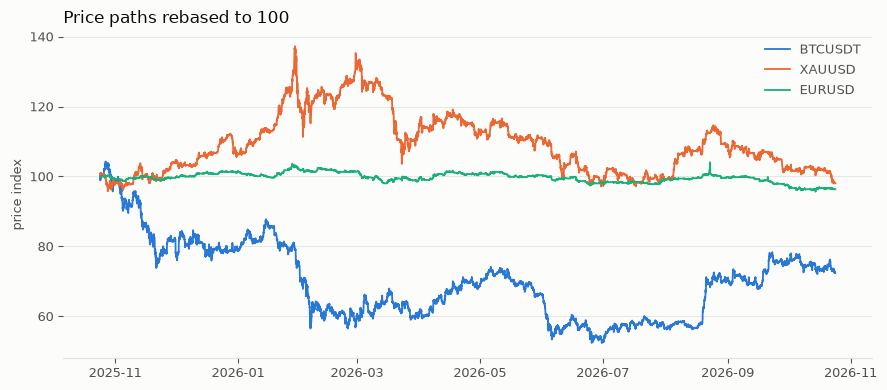

In [3]:
eda.plot_rebased(dfs);

## 2. Levels vs returns
Two trending series show a high *level* correlation even when they are unrelated. Returns remove the trend, so the return correlation is the honest relationship.

,levels,returns
pair,,
BTC-XAU,-0.189,0.269
BTC-EUR,0.131,0.112
XAU-EUR,0.645,0.346


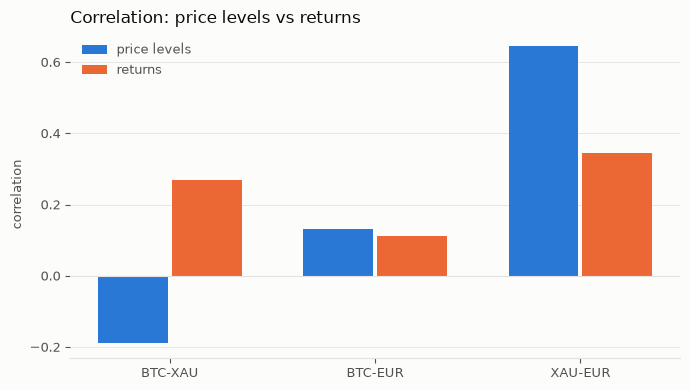

In [4]:
display(eda.levels_vs_returns_corr(dfs).round(3))
eda.plot_corr(dfs);

## 3. Volatility by hour (UTC)
Markets are not equally active all day. Strategies and risk limits should know this.

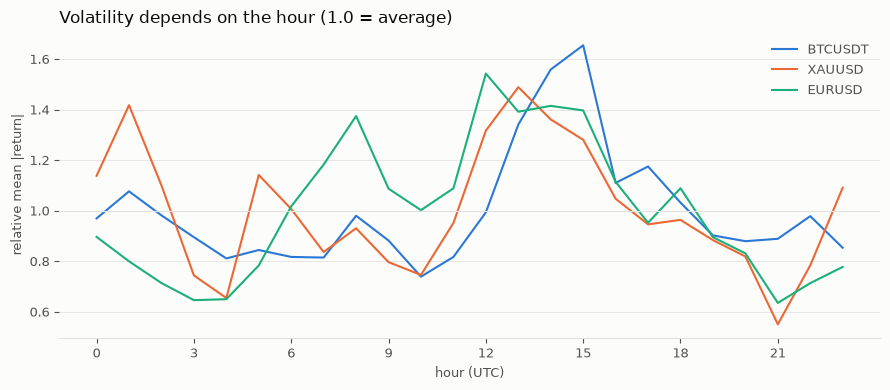

In [5]:
eda.plot_hour(dfs);

## 4. Volatility clustering
The direction of the next candle is almost unpredictable, but the *size* of moves is persistent.

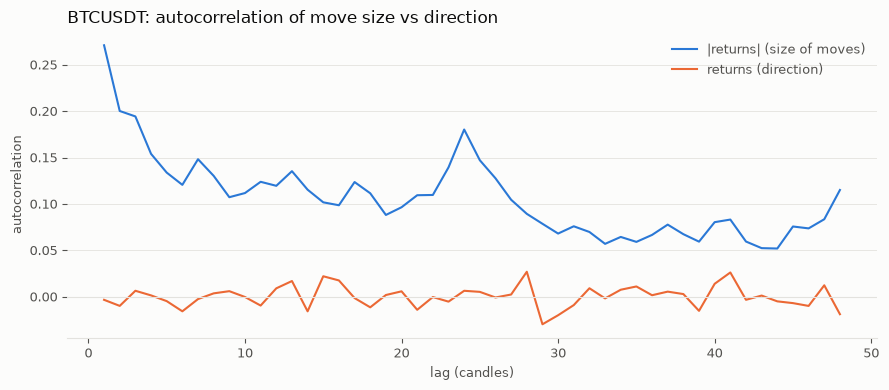

In [6]:
eda.plot_acf(dfs['BTCUSDT']);

## 5. Do liquidity sweeps carry information?
Forward 4-candle return in basis points. The t-statistic is divided by sqrt(4) of the sample size because neighbouring forward windows overlap. A value inside roughly +-2 means: no evidence yet.

In [7]:
for symbol, df in dfs.items():
    print(symbol)
    display(eda.sweep_forward_returns(df, horizon=4).round(2))

BTCUSDT


,n,mean_bps,hit_rate_up,t_adj
group,,,,
all candles,8657,-1.64,0.50,-0.83
after bull sweep,370,2.63,0.56,0.24
after bear sweep,436,1.78,0.50,0.20


XAUUSD


,n,mean_bps,hit_rate_up,t_adj
group,,,,
all candles,8657,0.04,0.50,0.03
after bull sweep,433,-6.91,0.48,-1.23
after bear sweep,455,2.07,0.56,0.40


EURUSD


,n,mean_bps,hit_rate_up,t_adj
group,,,,
all candles,8657,-0.18,0.45,-0.61
after bull sweep,408,-0.76,0.46,-0.58
after bear sweep,357,-0.97,0.45,-0.77


## What we learned
Fill this in after running: which pairs are really correlated, which hours matter, and whether sweeps show any edge on their own. Phase 6 (ML) starts from these honest baselines.